# LM1 Lab — Exponentials, Logarithms and Compounding

Companion notebook to **From Calculus to Kelly, LM1**. It rebuilds every exhibit and computational example in the module from verified price files, and solves the computational practice problems.

| Part | Rebuilds |
|:--|:--|
| 1 | Total-return series from raw closes, dividends and the split; the case (Exhibit 1) and the price/dividend split (Example 1) |
| 2 | Logarithms and log-scale charts (Exhibits 2–3) |
| 3 | Compounding frequency and the number $e$ (Exhibits 4–5, Examples 2–3) |
| 4 | Holding-period, annualized and continuously compounded returns (Exhibits 6–7, Examples 4–6) |
| 5 | Aggregation across time, positions and currencies (Exhibit 8, Examples 7–8) |
| 6 | Growth equations, doubling, drawdowns and recovery (Exhibits 9–12, Examples 9–10) |
| 7 | Practice-problem solutions and an extension exercise |

**Data.** `data/` holds a snapshot of FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08) and 0050 cash dividends from `TaiwanStockDividendResult`, retrieved 2026-10-10. Every close was checked against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend days and the two split days, which Part 1 handles explicitly.

**Environment.** `uv pip install polars pyarrow numpy matplotlib`.

In [1]:
import math
from datetime import date
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
BASE = date(2014, 10, 31)                     # last close before the first daily return
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Total-return series and the case

On an ex-dividend day $t$ the total return is $R_t=(P_t+D_t)/P_{t-1}-1$; on a split day with ratio $k$ it is $P_t/(P_{t-1}/k)-1$. 0050 split 4-for-1 on **2025-06-18**; 00631L split 22-for-1 on **2026-03-31** and paid no dividends in the sample.

In [2]:
SPLITS = {"0050": ("2025-06-18", 4.0), "00631L": ("2026-03-31", 22.0)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    gap = (pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs()
    bad = df.with_columns(gap.alias("gap")).filter(pl.col("gap") > 0.005)
    expected = (set(div["date"]) if sym == "0050" else set()) | {SPLITS[sym][0]}
    unexplained = sorted(set(bad["date"]) - expected)
    print(f"{sym}: {df.height} rows, checksum mismatches {bad.height}, unexplained {unexplained}")
    assert not unexplained
    return df

def total_returns(sym):
    df = load_raw(sym)
    sd, k = SPLITS[sym]
    d = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
         else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(pl.lit(k)).otherwise(pl.lit(1.0)).alias("k"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("k").alias(f"k_{sym}")))

raw0050, raw631 = total_returns("0050"), total_returns("00631L")

def add_returns(df, sym):
    R = (pl.col(f"P_{sym}") + pl.col(f"D_{sym}")) / (pl.col(f"P_{sym}").shift(1) / pl.col(f"k_{sym}")) - 1
    return df.with_columns(R.alias(f"R_{sym}"))

# (a) 0050 on its own trading days; (b) the series of the module, aligned with 00631L on common dates (as in LM3)
own = add_returns(raw0050, "0050").drop_nulls("R_0050").with_columns(pl.col("date").str.to_date())
aligned = (add_returns(add_returns(raw0050.join(raw631, on="date", how="inner").sort("date"), "0050"), "00631L")
           .drop_nulls("R_0050").with_columns(pl.col("date").str.to_date()))
R = aligned["R_0050"].to_numpy(); RL = aligned["R_00631L"].to_numpy()
dates = [BASE] + aligned["date"].to_list()
W = np.concatenate([[1.0], np.cumprod(1 + R)]); WL = np.concatenate([[1.0], np.cumprod(1 + RL)])
print(f"own series: {own.height} returns; aligned series: {aligned.height} returns")
print(f"growth factor: own {np.prod(1 + own['R_0050'].to_numpy()):.6f}  aligned {W[-1]:.6f}")

0050: 2907 rows, checksum mismatches 23, unexplained []
00631L: 2908 rows, checksum mismatches 1, unexplained []
own series: 2906 returns; aligned series: 2902 returns
growth factor: own 10.022465  aligned 10.022465


In [3]:
# Exhibit 1: one growth factor, three returns
G = W[-1]; lnG = math.log(G)
days = (dates[-1] - BASE).days; T = days / 365.25
RG = G ** (1 / T) - 1; g = lnG / T
case = {"G": G, "NT$100,000 ->": 100_000 * G, "HPR": G - 1, "days": days, "T (years)": T,
        "annualized R_G": RG, "log growth ln G": lnG, "continuously compounded g": g}
for k, v in case.items():
    print(f"{k:28s} {v:,.6f}")
assert round(G, 4) == 10.0225 and round(RG, 4) == 0.2130 and round(g, 4) == 0.1931 and round(lnG, 4) == 2.3048
print(f"check: ln(1+R_G) = {math.log1p(RG):.6f} = g;  simple-interest 'annualization' (G-1)/T = {(G - 1) / T:.2%}")

G                            10.022465
NT$100,000 ->                1,002,246.510286
HPR                          9.022465
days                         4,360.000000
T (years)                    11.937029
annualized R_G               0.212983
log growth ln G              2.304829
continuously compounded g    0.193082
check: ln(1+R_G) = 0.193082 = g;  simple-interest 'annualization' (G-1)/T = 75.58%


In [4]:
# Example 1: split the log growth into price and dividends
P0 = float(raw0050["P_0050"][0]); P1 = float(raw0050["P_0050"][-1]) * 4        # base close; last close in pre-split shares
G_price = P1 / P0
exd = aligned.filter(pl.col("D_0050") > 0)
div_log = float(np.log1p((exd["D_0050"] / exd["P_0050"]).to_numpy()).sum())
print(f"P0 = {P0}, P1 (pre-split shares) = {P1:.2f}, G_price = {G_price:.4f}, price return = {G_price - 1:.2%}")
print(f"ln G_price = {math.log(G_price):.4f} + dividends {div_log:.4f} = {math.log(G_price) + div_log:.4f}  (ln G = {lnG:.4f})")
print(f"{exd.height} dividends; share of log growth {div_log / lnG:.1%}; doublings {math.log(G_price)/math.log(2):.3f} + {div_log/math.log(2):.3f} = {lnG/math.log(2):.3f}")
assert abs(math.log(G_price) + div_log - lnG) < 1e-12

P0 = 65.3, P1 (pre-split shares) = 459.80, G_price = 7.0413, price return = 604.13%
ln G_price = 1.9518 + dividends 0.3530 = 2.3048  (ln G = 2.3048)
22 dividends; share of log growth 15.3%; doublings 2.816 + 0.509 = 3.325


## Part 2 — Logarithms and log-scale charts

Change of base: $\log_b x=\ln x/\ln b$ (eq. 1.3). On a log axis equal distances are equal ratios and constant growth $W_0e^{gt}$ is a straight line.

In [5]:
print(f"ln G = {lnG:.4f}; doublings log2 G = {lnG / math.log(2):.3f}; tenfold increases log10 G = {lnG / math.log(10):.3f}; ln 10 = {math.log(10):.4f}")
print(f"log2(1000) = {math.log(1000) / math.log(2):.2f}")
print(f"laws: 1.05^-1 = {1.05 ** -1:.4f};  1.01725^(1/12) - 1 = {1.01725 ** (1 / 12) - 1:.4%}")
prev = BASE
for lev in (2, 4, 8):
    k = int(np.argmax(W >= lev))
    print(f"first close >= {lev}: {dates[k]}  ({(dates[k] - prev).days / 365.25:.1f} years after the previous level)")
    prev = dates[k]
for a, b in (("2015-04-27", "2015-08-24"), ("2025-01-07", "2025-04-09")):
    ia, ib = dates.index(date.fromisoformat(a)), dates.index(date.fromisoformat(b))
    print(f"{a} -> {b}: drop {W[ia] - W[ib]:.2f} units, {W[ib] / W[ia] - 1:.1%}, {math.log(W[ib] / W[ia]):.2f} log points")

ln G = 2.3048; doublings log2 G = 3.325; tenfold increases log10 G = 1.001; ln 10 = 2.3026
log2(1000) = 9.97
laws: 1.05^-1 = 0.9524;  1.01725^(1/12) - 1 = 0.1426%
first close >= 2: 2020-11-11  (6.0 years after the previous level)
first close >= 4: 2024-07-04  (3.6 years after the previous level)
first close >= 8: 2026-04-27  (1.8 years after the previous level)
2015-04-27 -> 2015-08-24: drop 0.23 units, -21.0%, -0.24 log points
2025-01-07 -> 2025-04-09: drop 1.18 units, -27.5%, -0.32 log points


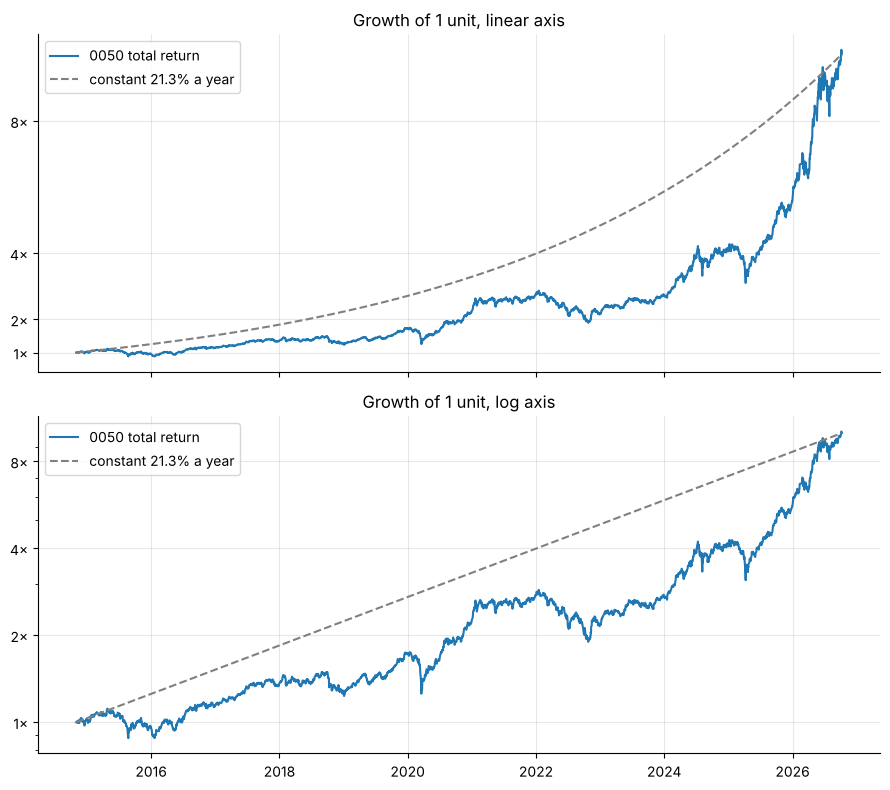

In [6]:
# Exhibit 3: linear and log axes, with the constant-rate path and doubling gridlines
t = np.array([(d - BASE).days / 365.25 for d in dates]); path = G ** (t / T)
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
for ax, scale in zip(axes, ("linear", "log")):
    ax.plot(dates, W, label="0050 total return"); ax.plot(dates, path, "--", color="grey", label=f"constant {RG:.1%} a year")
    ax.set_yscale(scale); ax.set_yticks([1, 2, 4, 8]); ax.set_yticklabels(["1×", "2×", "4×", "8×"])
    ax.set_title(f"Growth of 1 unit, {scale} axis"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## Part 3 — Compounding frequency and the number $e$

EAR $=(1+r^{(n)}/n)^n-1$ (eq. 1.4); continuous limit $e^r-1$ (eqs. 1.6–1.8).

In [7]:
FREQ = [("Annual", 1), ("Semiannual", 2), ("Quarterly", 4), ("Monthly", 12), ("Weekly", 52), ("Daily", 365)]
ear = pl.DataFrame({"compounding": [f for f, _ in FREQ] + ["Continuous"], "n": [n for _, n in FREQ] + [None]})
ear = ear.with_columns(
    pl.when(pl.col("n").is_null()).then(None).otherwise(pl.lit(0.15) / pl.col("n")).alias("periodic at 15%"),
    pl.when(pl.col("n").is_null()).then(pl.lit(math.expm1(0.01725))).otherwise((1 + pl.lit(0.01725) / pl.col("n")) ** pl.col("n") - 1).alias("EAR at 1.725%"),
    pl.when(pl.col("n").is_null()).then(pl.lit(math.expm1(0.15))).otherwise((1 + pl.lit(0.15) / pl.col("n")) ** pl.col("n") - 1).alias("EAR at 15%"))
ear   # Exhibit 4

compounding,n,periodic at 15%,EAR at 1.725%,EAR at 15%
str,i64,f64,f64,f64
"""Annual""",1,0.150000,0.017250,0.150000
"""Semiannual""",2,0.075000,0.017324,0.155625
"""Quarterly""",4,0.037500,0.017362,0.158650
"""Monthly""",12,0.012500,0.017387,0.160755
"""Weekly""",52,0.002885,0.017397,0.161583
"""Daily""",365,0.000411,0.017399,0.161798
"""Continuous""",null,null,0.017400,0.161834


In [8]:
# Exhibit 5: Bernoulli's sequence, and the series sum 1/k!
bern = pl.DataFrame({"n": [1, 2, 4, 12, 52, 365, 8760, 525600]}).with_columns(
    ((1 + 1 / pl.col("n").cast(pl.Float64)) ** pl.col("n")).alias("(1+1/n)^n")).with_columns(
    (pl.lit(math.e) - pl.col("(1+1/n)^n")).alias("distance to e"))
print([round(sum(1 / math.factorial(j) for j in range(k + 1)), 6) for k in range(1, 7)])
bern

[2.0, 2.5, 2.666667, 2.708333, 2.716667, 2.718056]


n,(1+1/n)^n,distance to e
i64,f64,f64
1,2.000000,0.718282
2,2.250000,0.468282
4,2.441406,0.276876
12,2.613035,0.105247
52,2.692597,0.025685
365,2.714567,0.003714
8760,2.718127,0.000155
525600,2.718279,0.000003


整存整付: periodic 0.14375%, EAR 1.7387%, interest NT$17,387;  存本取息: NT$17,250; difference NT$137
存本取息 monthly payments (31, 30, 28 days): [1465.07, 1417.81, 1323.29]
card: daily rate 0.041096%, simple NT$15,000, daily compounding 16.180% = NT$16,180, continuous 16.183%
stated daily-compounded rate that yields a 15% EAR: 13.979%
KC: EAR of 5.85% monthly 6.0094%; cc equivalents 5.8358% and 5.8269%


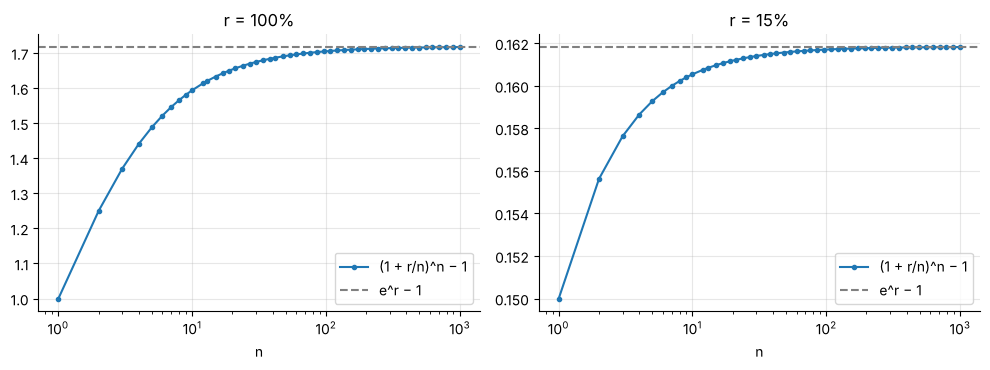

In [9]:
# Example 2 (deposit) and Example 3 (credit card), plus the Section 3 knowledge check
dep = (1 + 0.01725 / 12) ** 12 - 1
print(f"整存整付: periodic {0.01725 / 12:.5%}, EAR {dep:.4%}, interest NT${1e6 * dep:,.0f};  存本取息: NT${1e6 * 0.01725:,.0f}; difference NT${1e6 * (dep - 0.01725):,.0f}")
print("存本取息 monthly payments (31, 30, 28 days):", [round(1e6 * 0.01725 * d / 365, 2) for d in (31, 30, 28)])
card = (1 + 0.15 / 365) ** 365 - 1
print(f"card: daily rate {0.15 / 365:.6%}, simple NT$15,000, daily compounding {card:.3%} = NT${1e5 * card:,.0f}, continuous {math.expm1(0.15):.3%}")
print(f"stated daily-compounded rate that yields a 15% EAR: {365 * (1.15 ** (1 / 365) - 1):.3%}")
print(f"KC: EAR of 5.85% monthly {(1 + 0.0585 / 12) ** 12 - 1:.4%}; cc equivalents {12 * math.log1p(0.0585 / 12):.4%} and {math.log(1.06):.4%}")

# convergence picture: EAR vs n at r = 100% and r = 15%
ns = np.unique(np.round(np.logspace(0, 3, 60)).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, r in zip(axes, (1.0, 0.15)):
    ax.semilogx(ns, (1 + r / ns) ** ns - 1, marker=".", label="(1 + r/n)^n − 1")
    ax.axhline(math.expm1(r), color="grey", ls="--", label="e^r − 1"); ax.set_title(f"r = {r:.0%}"); ax.set_xlabel("n"); ax.legend()
plt.tight_layout(); plt.show()

## Part 4 — Holding-period, annualized and continuously compounded returns

$R_G=G^{1/T}-1$ (1.9), $g=\ln G/T=\ln(1+R_G)$ (1.10); over $h$ days or $N$ sessions, $R_G=(1+R_h)^{365/h}-1$ or $(1+R_N)^{D/N}-1$ (1.11).

In [10]:
# Exhibit 6 values and Example 4 (the same growth quoted at several frequencies)
print(f"HPR {G - 1:.2%}  R_G {RG:.3%}  ln G {lnG:.4f}  g {g:.3%};  e^g - 1 = {math.expm1(g):.3%}")
for n in (1, 2, 4, 12, 52, 365):
    print(f"  stated rate compounded {n:>3}x a year with the same EAR: {n * ((1 + RG) ** (1 / n) - 1):.2%}")
print(f"  continuous: {math.log1p(RG):.2%}")

HPR 902.25%  R_G 21.298%  ln G 2.3048  g 19.308%;  e^g - 1 = 21.298%
  stated rate compounded   1x a year with the same EAR: 21.30%
  stated rate compounded   2x a year with the same EAR: 20.27%
  stated rate compounded   4x a year with the same EAR: 19.78%
  stated rate compounded  12x a year with the same EAR: 19.46%
  stated rate compounded  52x a year with the same EAR: 19.34%
  stated rate compounded 365x a year with the same EAR: 19.31%
  continuous: 19.31%


In [11]:
# Exhibit 7: trailing windows (start = last close on or before the nominal date)
IDX = {d: k for k, d in enumerate(dates)}
def on_or_before(d):
    while d not in IDX:
        d = date.fromordinal(d.toordinal() - 1)
    return d
END = dates[-1]
rows = []
for label, nominal, yrs in [("3 months", date(2026, 7, 8), 0.25), ("6 months", date(2026, 4, 8), 0.5), ("1 year", date(2025, 10, 8), 1.0),
                            ("3 years", date(2023, 10, 8), 3.0), ("5 years", date(2021, 10, 8), 5.0), ("10 years", date(2016, 10, 8), 10.0),
                            ("Since 31 Oct 2014", BASE, T)]:
    s = on_or_before(nominal); Gw = W[IDX[END]] / W[IDX[s]]
    rows.append({"window": label, "from": s, "HPR": Gw - 1, "annualized": Gw ** (1 / yrs) - 1, "cont. comp.": math.log(Gw) / yrs})
pl.DataFrame(rows)

window,from,HPR,annualized,cont. comp.
str,date,f64,f64,f64
"""3 months""",2026-07-08,0.090268,0.412968,0.345693
"""6 months""",2026-04-08,0.459885,1.131264,0.756715
"""1 year""",2025-10-08,0.917142,0.917142,0.650835
"""3 years""",2023-10-06,2.968601,0.583237,0.459471
"""5 years""",2021-10-08,2.950460,0.316223,0.274766
"""10 years""",2016-10-07,7.751978,0.242255,0.216928
"""Since 31 Oct 2014""",2014-10-31,9.022465,0.212983,0.193082


In [12]:
# Example 5: a 90-day return annualized five ways
a90, b90 = date(2026, 7, 9), date(2026, 10, 7)
G90 = W[IDX[b90]] / W[IDX[a90]]; N90 = IDX[b90] - IDX[a90]; h = (b90 - a90).days
print(f"{h} days, {N90} sessions, HPR {G90 - 1:.2%}")
print(f"calendar {G90 ** (365 / h) - 1:.2%} | D=252 {G90 ** (252 / N90) - 1:.2%} | D=243.8 {G90 ** (243.8 / N90) - 1:.2%} | "
      f"cont. {math.log(G90) * 365 / h:.2%} | simple {(G90 - 1) * 365 / h:.2%}")

# Example 6: mean daily log return x 252 vs x observations per year
lr = np.log1p(R); obs = len(R) / T
print(f"{len(R)} obs, mean {lr.mean():.6%}; x252 = {lr.mean() * 252:.2%}; obs/yr = {obs:.1f}; x obs/yr = {lr.mean() * obs:.2%} (= g); "
      f"EAR via 252: {math.expm1(lr.mean() * 252):.2%}")

# TWSE sessions per year: days on which 0050 or 00631L traded
u = pl.concat([pl.read_csv(DATA / "0050_daily_raw.csv").select("date"), pl.read_csv(DATA / "00631L_daily_raw.csv").select("date")]).unique()
per_year = (u.with_columns(pl.col("date").str.slice(0, 4).cast(pl.Int32).alias("year")).filter(pl.col("year").is_between(2015, 2025))
             .group_by("year").len().sort("year"))
print(per_year["len"].to_list(), "mean", per_year["len"].mean())

90 days, 61 sessions, HPR 10.33%
calendar 48.99% | D=252 50.10% | D=243.8 48.13% | cont. 39.87% | simple 41.89%
2902 obs, mean 0.079422%; x252 = 20.01%; obs/yr = 243.1; x obs/yr = 19.31% (= g); EAR via 252: 22.16%
[244, 244, 246, 247, 242, 245, 244, 246, 239, 242, 243] mean 243.8181818181818


## Part 5 — Aggregation across time, positions and currencies

Across time $\ln G=\sum_t r_t$ (1.12); across positions $R_p=\sum_i w_iR_i$ (1.13) and $r_p\ge\sum_iw_ir_i$ (1.14); across factors $r^{\text{TWD}}=r^{\text{USD}}+r^{\text{FX}}$ (1.15).

In [13]:
# Exhibit 8: two-year blocks
bounds = [BASE] + [on_or_before(date(y, 10, 31)) for y in (2016, 2018, 2020, 2022, 2024)] + [END]
blocks = pl.DataFrame([{"start": a, "end": b, "days": (b - a).days, "R": W[IDX[b]] / W[IDX[a]] - 1,
                        "r": math.log(W[IDX[b]] / W[IDX[a]])} for a, b in zip(bounds[:-1], bounds[1:])])
print("sum of r:", round(blocks["r"].sum(), 6), " ln G:", round(lnG, 6), " sum of printed r (4 dp):", round(blocks["r"].round(4).sum(), 4))
print("sum of printed simple returns (2 dp, %):", round((blocks["R"] * 100).round(2).sum(), 2))
blocks

sum of r: 2.304829  ln G: 2.304829  sum of printed r (4 dp): 2.3048
sum of printed simple returns (2 dp, %): 332.08


start,end,days,R,r
date,date,i64,f64,f64
2014-10-31,2016-10-31,731,0.160349,0.148721
2016-10-31,2018-10-31,730,0.140628,0.131579
2018-10-31,2020-10-30,730,0.435611,0.361590
2020-10-30,2022-10-31,731,0.023495,0.023224
2022-10-31,2024-10-30,730,1.064731,0.725000
2024-10-30,2026-10-08,708,1.496064,0.914715


In [14]:
# Example 7: 50/50 buy-and-hold of 0050 and 00631L, correct vs averaged log returns
GL = WL[-1]; Gp = 0.5 * G + 0.5 * GL; avg = 0.5 * lnG + 0.5 * math.log(GL)
print(f"00631L G {GL:.4f} (ln {math.log(GL):.4f}); portfolio G {Gp:.2f} = +{Gp - 1:.0%}; ln {math.log(Gp):.3f}")
print(f"average log {avg:.4f} -> e^avg {math.exp(avg):.2f} = +{math.exp(avg) - 1:.0%} (= sqrt(G*GL) {math.sqrt(G * GL):.2f}); "
      f"understatement {(Gp - math.exp(avg)) * 100:.0f} pp")

# Example 8: a USD asset seen from Taiwan (hypothetical numbers)
Rusd, Rfx = 0.20, 29.6 / 32.0 - 1
print(f"FX {Rfx:.2%}; exact {(1 + Rusd) * (1 + Rfx) - 1:.2%}; logs {math.log1p(Rusd):.5f} + {math.log1p(Rfx):.5f} = {math.log1p(Rusd) + math.log1p(Rfx):.5f}; "
      f"naive {Rusd + Rfx:.2%}; cross term {Rusd * Rfx:.2%}")
print(f"KC: log returns +0.1/-0.1 -> simple {math.expm1(0.1):.2%}, {math.expm1(-0.1):.2%}; portfolio {0.5 * math.expm1(0.1) + 0.5 * math.expm1(-0.1):.2%}")

00631L G 44.5446 (ln 3.7965); portfolio G 27.28 = +2628%; ln 3.306
average log 3.0507 -> e^avg 21.13 = +2013% (= sqrt(G*GL) 21.13); understatement 615 pp
FX -7.50%; exact 11.00%; logs 0.18232 + -0.07796 = 0.10436; naive 12.50%; cross term -1.50%
KC: log returns +0.1/-0.1 -> simple 10.52%, -9.52%; portfolio 0.50%


## Part 6 — Growth equations, doubling, drawdowns and recovery

$T=\ln(W_T/W_0)/\ln(1+R)$, $R=(W_T/W_0)^{1/T}-1$ (1.16); recovery gain $D/(1-D)$ (1.17) and log distance $-\ln(1-D)$.

In [15]:
# Exhibit 9: doubling times
pl.DataFrame({"R": [0.01725, 0.04, 0.08, 0.15, RG]}).with_columns(
    (pl.lit(math.log(2)) / pl.col("R").log1p()).alias("exact T2"), (72 / (100 * pl.col("R"))).alias("rule of 72"))

R,exact T2,rule of 72
f64,f64,f64
0.017250,40.528031,41.739130
0.040000,17.672988,18.000000
0.080000,9.006468,9.000000
0.150000,4.959484,4.800000
0.212983,3.589905,3.380558


In [16]:
# Example 9: retirement target
x = 20 / 3
print(f"required R {x ** (1 / 25) - 1:.2%}, g {math.log(x) / 25:.2%}; time at 6%: {math.log(x) / math.log(1.06):.2f} years; "
      f"wealth at 60: NT${3e6 * 1.06 ** 25:,.0f}")
print(f"nominal with 2% inflation: {math.expm1(math.log(x) / 25 + math.log(1.02)):.2%} = {(x ** (1 / 25)) * 1.02 - 1:.2%}")

# Exhibit 10: recovery arithmetic
D = pl.DataFrame({"D": [0.10, 0.20, 0.25, 1 / 3, 0.50, 0.75, 0.90]})
D.with_columns((pl.col("D") / (1 - pl.col("D"))).alias("gain needed"), (-(1 - pl.col("D")).log()).alias("log distance")).with_columns(
    (pl.col("log distance") / math.log(1.08)).alias("years at 8%"), (pl.col("log distance") / g).alias("years at R_G"))

required R 7.88%, g 7.59%; time at 6%: 32.56 years; wealth at 60: NT$12,875,612
nominal with 2% inflation: 10.04% = 10.04%


D,gain needed,log distance,years at 8%,years at R_G
f64,f64,f64,f64,f64
0.100000,0.111111,0.105361,1.369011,0.545677
0.200000,0.250000,0.223144,2.899435,1.155691
0.250000,0.333333,0.287682,3.738022,1.489945
0.333333,0.500000,0.405465,5.268446,2.099960
0.500000,1.000000,0.693147,9.006468,3.589905
0.750000,3.000000,1.386294,18.012937,7.179811
0.900000,9.000000,2.302585,29.918840,11.925407


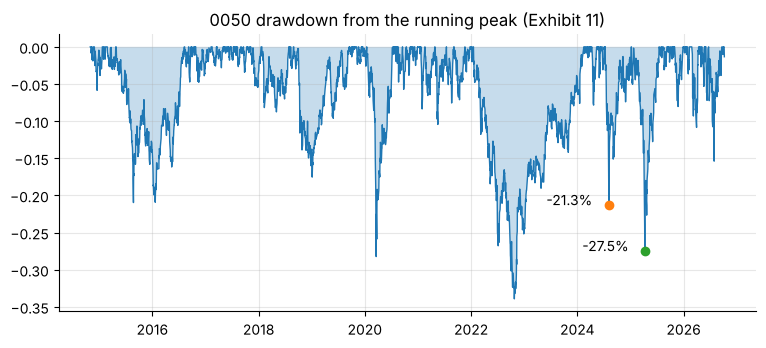

peak,trough,depth,gain needed,recovered,days to recover,sessions,days at g
date,date,f64,f64,date,i64,i64,i64
2015-04-27,2015-08-24,-0.209622,0.265217,2016-08-08,350,234,445
2018-08-30,2019-01-04,-0.175328,0.212604,2019-09-16,255,166,365
2020-01-14,2020-03-19,-0.282352,0.393441,2020-07-13,116,77,628
2022-01-17,2022-10-25,-0.339292,0.513528,2024-02-15,478,313,784
2024-07-11,2024-08-05,-0.213038,0.270710,2025-01-06,154,104,453
2025-01-07,2025-04-09,-0.274898,0.379116,2025-07-17,99,64,608
2026-06-22,2026-07-30,-0.153870,0.181852,2026-09-21,53,37,316


In [17]:
# Exhibits 11-12: drawdown curve and episodes deeper than 15%
dd = W / np.maximum.accumulate(W) - 1
episodes, in_dd = [], False
for k in range(1, len(W)):
    if dd[k] < 0 and not in_dd:
        in_dd, s0 = True, k - 1
    if in_dd and dd[k] >= 0:
        tr = s0 + int(np.argmin(dd[s0:k])); in_dd = False
        if dd[tr] <= -0.15:
            Dd = -dd[tr]
            episodes.append({"peak": dates[s0], "trough": dates[tr], "depth": -Dd, "gain needed": Dd / (1 - Dd), "recovered": dates[k],
                             "days to recover": (dates[k] - dates[tr]).days, "sessions": k - tr,
                             "days at g": round(-math.log1p(-Dd) / g * 365.25)})
ep = pl.DataFrame(episodes)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(dates, dd, 0, alpha=0.25); ax.plot(dates, dd, lw=1)
for d0 in (date(2024, 8, 5), date(2025, 4, 9)):
    ax.plot(d0, dd[dates.index(d0)], "o"); ax.annotate(f"{dd[dates.index(d0)]:.1%}", (d0, dd[dates.index(d0)]), xytext=(-45, 0), textcoords="offset points")
ax.set_title("0050 drawdown from the running peak (Exhibit 11)"); plt.show()
ep   # Exhibit 12

In [18]:
# Example 10: the 2024 and 2025 episodes
for d0 in ("2025-04-02", "2025-04-07", "2025-04-08", "2025-04-09", "2025-04-10"):
    i = IDX[date.fromisoformat(d0)]
    print(d0, f"R {W[i] / W[i - 1] - 1:+.2%}  drawdown {dd[i]:.2%}")
i7, i9 = IDX[date(2025, 4, 7)], IDX[date(2025, 4, 9)]
print(f"log split: {math.log1p(dd[i7 - 1]):.4f} + {math.log(W[i9] / W[i7 - 1]):.4f} = {math.log1p(dd[i9]):.4f};  "
      f"at g: {-math.log1p(dd[i9]) / g:.2f} years vs actual {99 / 365.25:.2f}")
missing = sorted(set(pl.read_csv(DATA / "00631L_daily_raw.csv")["date"]) - set(pl.read_csv(DATA / "0050_daily_raw.csv")["date"]))
print("sessions on which 0050 did not trade:", missing)

2025-04-02 R -0.17%  drawdown -12.71%
2025-04-07 R -10.00%  drawdown -21.44%
2025-04-08 R -3.25%  drawdown -23.99%
2025-04-09 R -4.60%  drawdown -27.49%
2025-04-10 R +9.99%  drawdown -20.25%
log split: -0.1359 + -0.1855 = -0.3214;  at g: 1.66 years vs actual 0.27


sessions on which 0050 did not trade: ['2025-06-11', '2025-06-12', '2025-06-13', '2025-06-16', '2025-06-17']


## Part 7 — Practice-problem solutions (computational) and an extension

In [19]:
L2 = math.log(2)
print("PP1 ", f"log2(25) = {math.log(25) / L2:.2f}")
print("PP2 ", f"{(1.01) ** 12 - 1:.2%}  (continuous {math.expm1(0.12):.2%})")
q = 1.006 ** 4 - 1
print("PP3 ", f"EAR {q:.4%}  r(12) {12 * ((1 + q) ** (1 / 12) - 1):.4%}  cc {math.log1p(q):.4%}")
print("PP4 ", f"{math.expm1(0.08):.2%}")
print("PP6 ", f"R_G {G_price ** (1 / T) - 1:.2%}  g_P {math.log(G_price) / T:.2%}  dividends {div_log / T:.2%}")
print("PP7 ", f"{1.06 ** 3 - 1:.2%}")
y = [0.2740, 0.4867, 0.3685]; G3 = np.prod([1 + v for v in y])
print("PP8 ", f"cum {G3 - 1:.2%}  ann {G3 ** (1 / 3) - 1:.2%}  logs {[round(math.log1p(v), 5) for v in y]} sum {sum(math.log1p(v) for v in y):.5f}  "
      f"cc {math.log(G3) / 3:.2%}  sum simple {sum(y):.2%}")
pp9 = 0.5 * (math.exp(0.3) + math.exp(-0.1))
print("PP9 ", f"r_p {math.log(pp9):.2%}  R_p {pp9 - 1:.2%}")
print("PP10", f"{1.04 * 1.05 - 1:.2%}  logs {math.log(1.04) + math.log(1.05):.5f}")
print("PP11", f"{math.log(4) / math.log(1.06):.2f}  {math.log(4) / 0.06:.2f}")
print("PP12", f"{5 ** (1 / 15) - 1:.2%}  (cc {math.log(5) / 15:.2%})")
print("PP13", f"{0.35 / 0.65:.2%}  {-math.log(0.65) / math.log(1.10):.2f} years  {0.65 * 1.3 - 1:.2%}")
print("PP14", f"{0.33929 / 0.66071:.2%}  {-math.log(0.66071):.4f}  {-math.log(0.66071) / 0.19308:.3f} years = {-math.log(0.66071) / 0.19308 * 365.25:.0f} days")

PP1  log2(25) = 4.64
PP2  12.68%  (continuous 12.75%)
PP3  EAR 2.4217%  r(12) 2.3952%  cc 2.3928%
PP4  8.33%
PP6  R_G 17.76%  g_P 16.35%  dividends 2.96%
PP7  19.10%
PP8  cum 159.20%  ann 37.37%  logs [0.24216, 0.39656, 0.31372] sum 0.95244  cc 31.75%  sum simple 112.92%
PP9  r_p 11.99%  R_p 12.73%
PP10 9.20%  logs 0.08801
PP11 23.79  23.10
PP12 11.33%  (cc 10.73%)
PP13 53.85%  4.52 years  -15.50%
PP14 51.35%  0.4144  2.146 years = 784 days


In [20]:
# PP15: ten calendar years 2015-2024
a, b = date(2014, 12, 31), date(2024, 12, 31)
G10 = W[IDX[b]] / W[IDX[a]]
m = (pl.col("date") > pl.lit(a)) & (pl.col("date") <= pl.lit(b))
sub = aligned.filter(m)["R_0050"].log1p()
n10, mu = sub.len(), sub.mean()
print(f"G {G10:.4f}  R_G {G10 ** 0.1 - 1:.2%}  g {math.log(G10) / 10:.2%}")
print(f"{n10} sessions ({n10 / 10:.1f}/yr), mean daily log {mu:.6%}; x252 {mu * 252:.2%} (EAR {math.expm1(mu * 252):.2%}); "
      f"x{n10 / 10:.1f} {mu * n10 / 10:.2%} (EAR {math.expm1(mu * n10 / 10):.2%})")

G 4.0030  R_G 14.88%  g 13.87%
2439 sessions (243.9/yr), mean daily log 0.056869%; x252 14.33% (EAR 15.41%); x243.9 13.87% (EAR 14.88%)


### Extension: drawdowns of a leveraged fund

Repeat Exhibit 12 for 00631L, the daily 2× fund (series `WL` above). For its April 2025 episode, compute the depth, the gain needed and the log distance, and compare the log distance with twice 0050's (0.3214). Why is the leveraged fund's log loss *more* than twice the index's in a crash, and what does that imply for its recovery time at a given growth rate? The variance-drag decomposition of LM3 gives the answer. A starting point:

In [21]:
ddL = WL / np.maximum.accumulate(WL) - 1
k = int(np.argmin(np.where([(date(2025, 1, 1) <= d <= date(2025, 6, 30)) for d in dates], ddL, 0.0)))
print(f"00631L 2025 trough {dates[k]}: depth {ddL[k]:.2%}, gain needed {-ddL[k] / (1 + ddL[k]):.2%}, "
      f"log distance {-math.log1p(ddL[k]):.4f} vs 2 x 0050's {2 * -math.log1p(dd[IDX[date(2025, 4, 9)]]):.4f}")

00631L 2025 trough 2025-04-09: depth -55.14%, gain needed 122.93%, log distance 0.8017 vs 2 x 0050's 0.6429
